In [2]:
from google.colab import files
uploaded = files.upload()

Saving movies_cleaned.csv to movies_cleaned.csv
Saving cast_cleaned.csv to cast_cleaned.csv
Saving crew_cleaned.csv to crew_cleaned.csv
Saving genres_cleaned.csv to genres_cleaned.csv
Saving movie_genres_cleaned.csv to movie_genres_cleaned.csv
Saving movie_keywords_cleaned.csv to movie_keywords_cleaned.csv


In [3]:
import pandas as pd

movies = pd.read_csv('movies_cleaned.csv')
genres = pd.read_csv('genres_cleaned.csv')
movie_genres = pd.read_csv('movie_genres_cleaned.csv')
cast = pd.read_csv('cast_cleaned.csv')
crew = pd.read_csv('crew_cleaned.csv')
movie_keywords = pd.read_csv('movie_keywords_cleaned.csv')

# **Univariate**

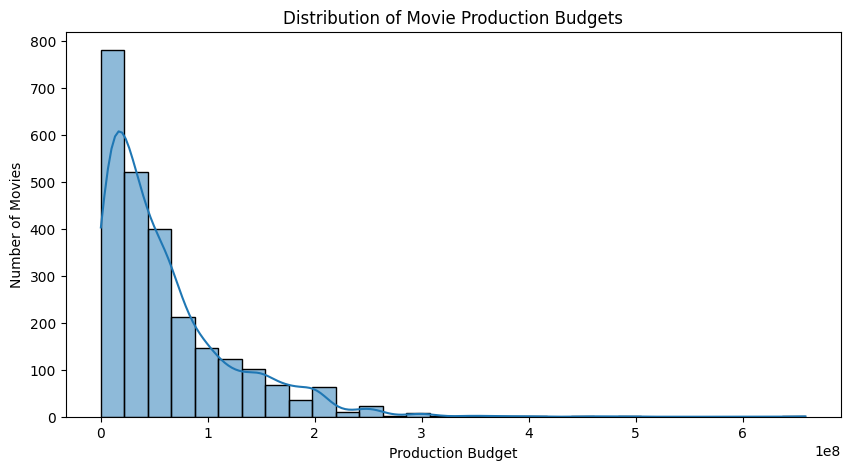

In [7]:
# 1.How are movie production budgets distributed across the dataset

#Create histogram with KDE
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(movies['budget'], bins=30, kde=True)

plt.title('Distribution of Movie Production Budgets')
plt.xlabel('Production Budget')
plt.ylabel('Number of Movies')

plt.show()

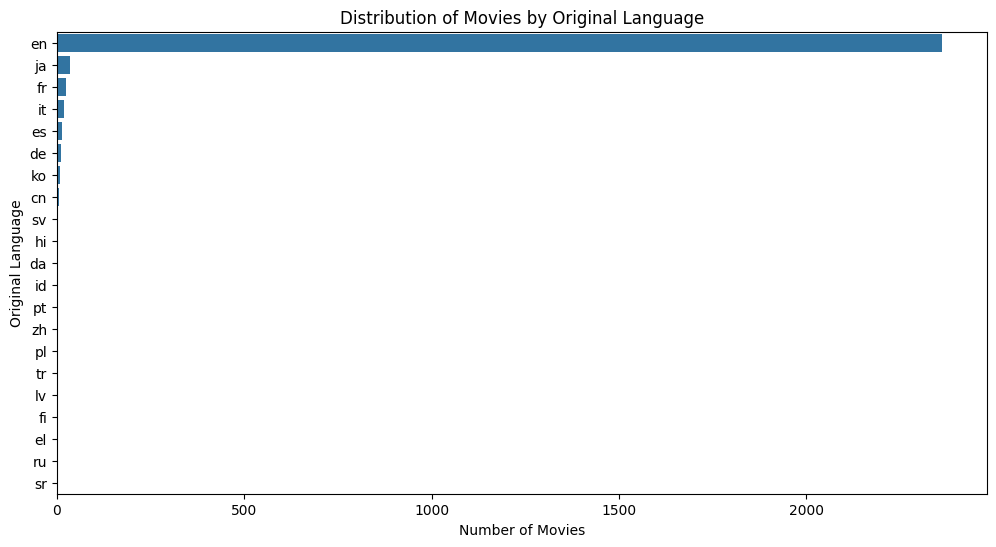

In [8]:
# 2.Which original languages are most commonly represented in the movie dataset

#Create horizontal plot
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.countplot(
    data=movies,
    y='original_language',
    order=movies['original_language'].value_counts().index
)

plt.title('Distribution of Movies by Original Language')
plt.xlabel('Number of Movies')
plt.ylabel('Original Language')

plt.show()

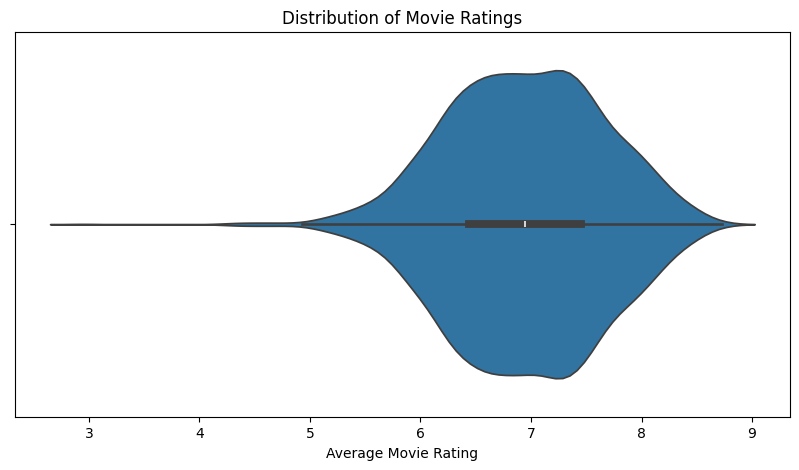

In [9]:
# 3.How are audience ratings distributed across the movies in the dataset

#Create violin plot
plt.figure(figsize=(10, 5))

sns.violinplot(x=movies['vote_average'])

plt.title('Distribution of Movie Ratings')
plt.xlabel('Average Movie Rating')

plt.show()

# **Bivariate**

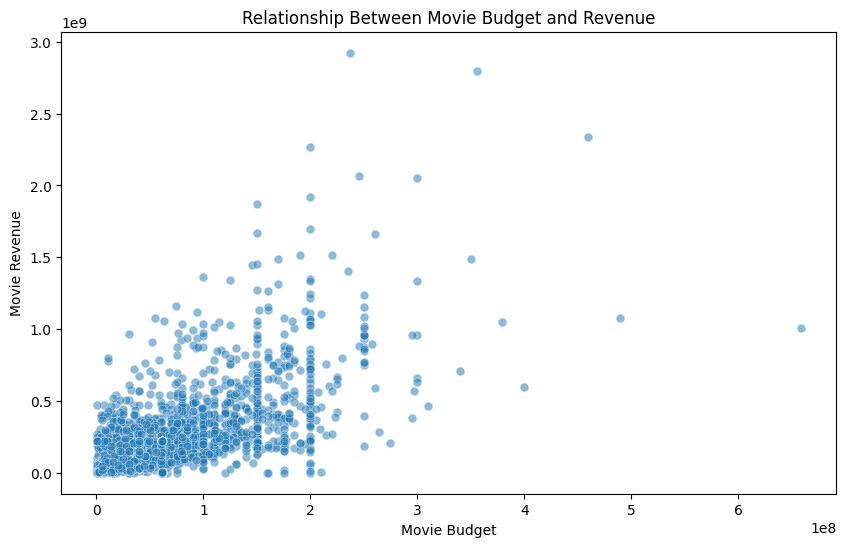

In [27]:
# 4.Is there a relationship between movie production budgets and revenue

#Create scatter plot
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=movies,
    x='budget',
    y='revenue',
    alpha=0.5,
    s=40
)

plt.title('Relationship Between Movie Budget and Revenue')
plt.xlabel('Movie Budget')
plt.ylabel('Movie Revenue')

plt.show()

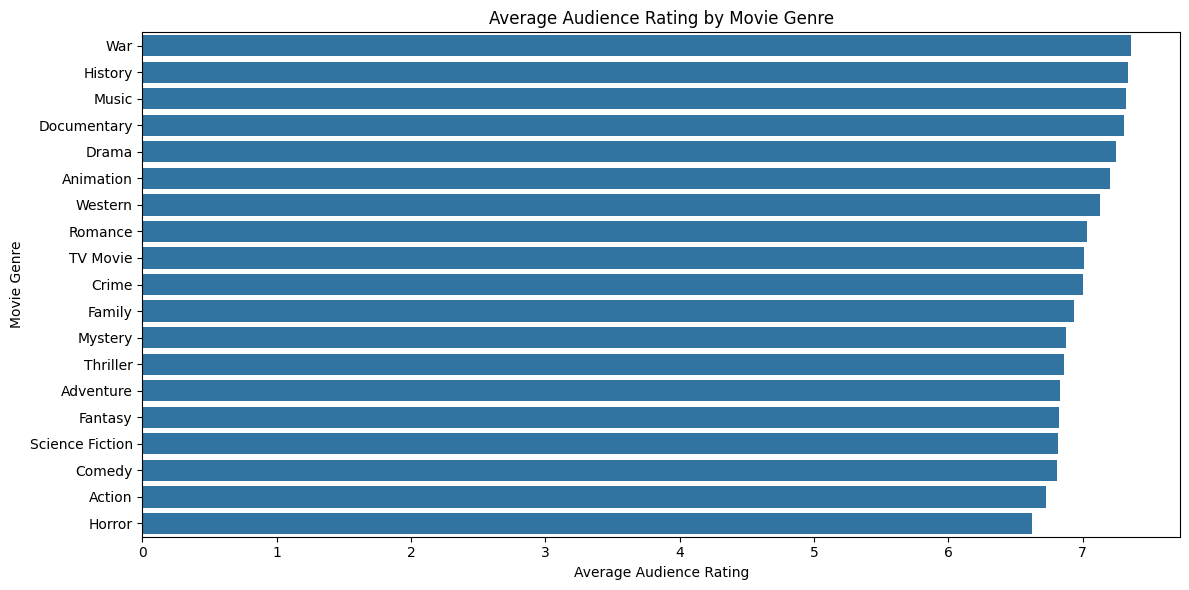

In [29]:
# 5.Which movie genres have the highest average audience ratings

genre_ratings = movie_genres

genre_ratings['genre_name'] = genre_ratings['genre_id'].map(genres.set_index('genre_id')['genre_name'])

genre_ratings['vote_average'] = genre_ratings['movie_id'].map(movies.set_index('movie_id')['vote_average'])

average_ratings = genre_ratings.groupby('genre_name')['vote_average'].mean()

average_ratings = average_ratings.sort_values(ascending=False)

# Create bar chart
plt.figure(figsize=(12, 6))

sns.barplot(
    x=average_ratings.values,
    y=average_ratings.index
)

plt.title('Average Audience Rating by Movie Genre')
plt.xlabel('Average Audience Rating')
plt.ylabel('Movie Genre')

plt.tight_layout()
plt.show()

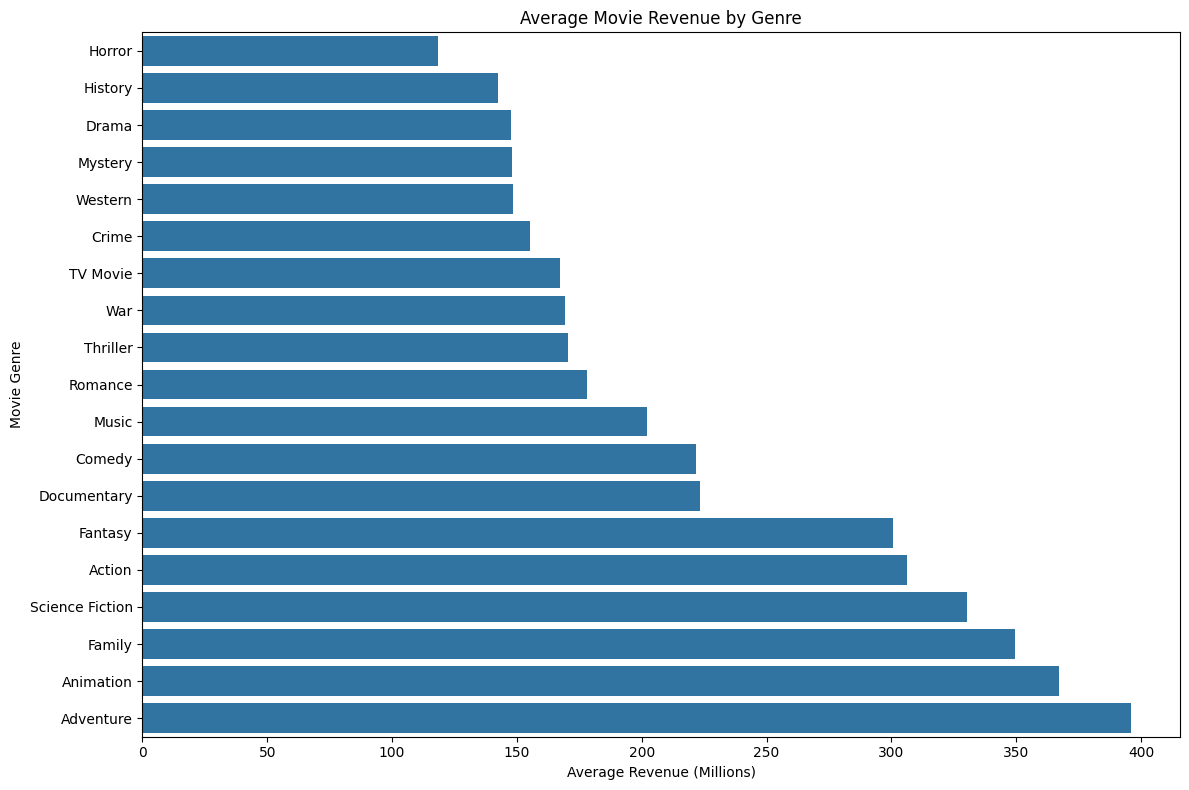

In [33]:
# 6.Which movie genres generate the highest average revenue

genre_revenue = movie_genres

genre_revenue['genre_name'] = genre_revenue['genre_id'].map(genres.set_index('genre_id')['genre_name'])
genre_revenue['revenue'] = genre_revenue['movie_id'].map(movies.set_index('movie_id')['revenue'])

average_revenue = genre_revenue.groupby('genre_name')['revenue'].mean()

average_revenue = average_revenue.sort_values()

# Create bar chart
plt.figure(figsize=(12, 8))

sns.barplot(
    x=average_revenue.values / 1000000,
    y=average_revenue.index
)

plt.title('Average Movie Revenue by Genre')
plt.xlabel('Average Revenue (Millions)')
plt.ylabel('Movie Genre')

plt.tight_layout()
plt.show()

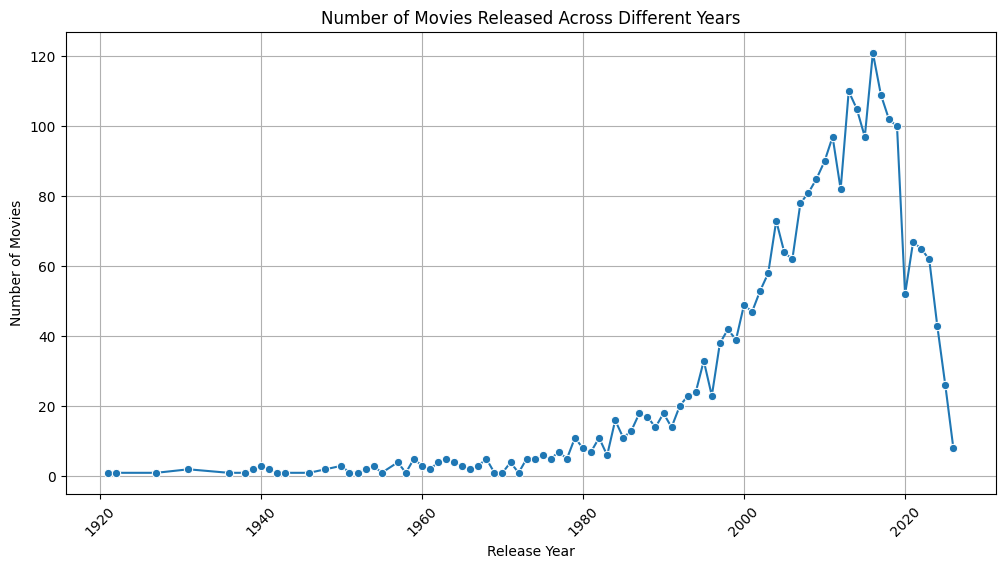

In [51]:
# 7.How does the number of movies released change across different years?

movies['release_date'] = pd.to_datetime(
    movies['release_date'], errors='coerce'
)

movies['release_year'] = movies['release_date'].dt.year

yearly_movies = movies['release_year'].value_counts().sort_index()

#Create line plot
plt.figure(figsize=(12, 6))
sns.lineplot(x=yearly_movies.index, y=yearly_movies.values, marker='o')

plt.title('Number of Movies Released Across Different Years')
plt.xlabel('Release Year')
plt.ylabel('Number of Movies')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

# **Multivariate**

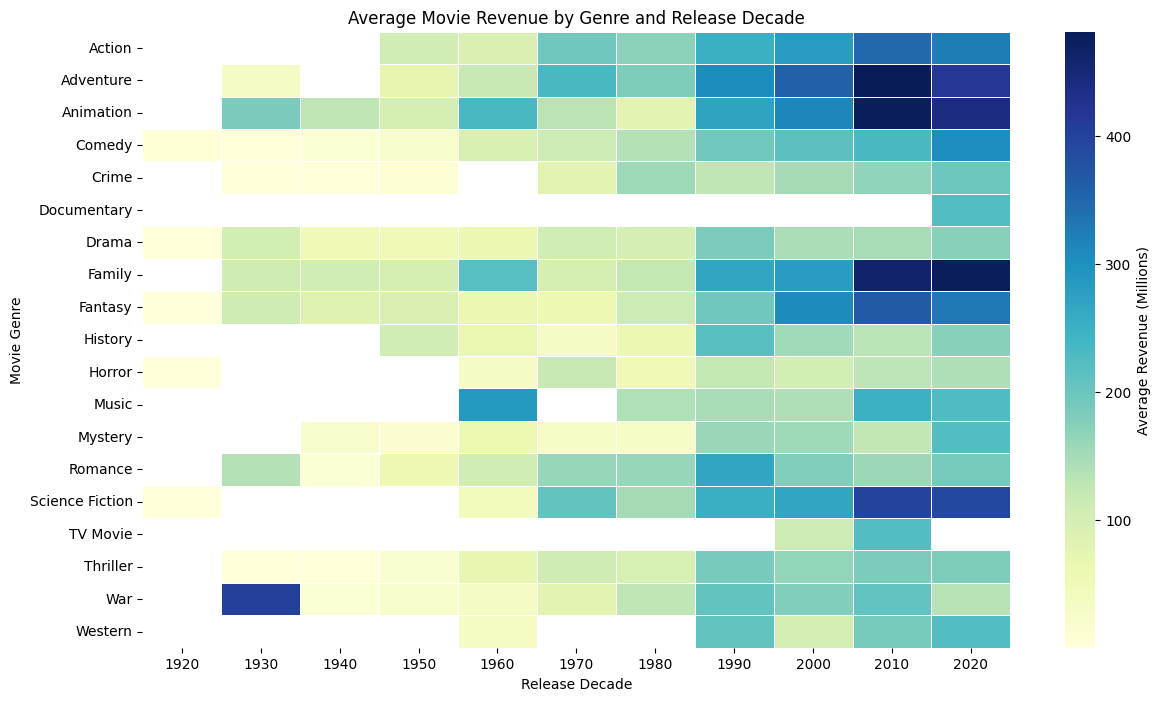

In [49]:
# 8.How does average movie revenue vary across different genres and release decades?
movies['release_year'] = pd.to_datetime(
    movies['release_date'], errors='coerce').dt.year

movies['release_decade'] = ((movies['release_year'] // 10) * 10)

genre_revenue = movie_genres

genre_revenue['genre_name'] = genre_revenue['genre_id'].map(genres.set_index('genre_id')['genre_name'])
genre_revenue['revenue'] = genre_revenue['movie_id'].map(movies.set_index('movie_id')['revenue'])
genre_revenue['release_decade'] = genre_revenue['movie_id'].map(movies.set_index('movie_id')['release_decade'])

revenue_heatmap = genre_revenue.pivot_table(
    index='genre_name',
    columns='release_decade',
    values='revenue',
    aggfunc='mean'
)

#Create heatmap
plt.figure(figsize=(14, 8))

sns.heatmap(
    revenue_heatmap / 1000000,
    annot=False,
    cmap='YlGnBu',
    linewidths=0.5,
    cbar_kws={'label': 'Average Revenue (Millions)'}
)

plt.title('Average Movie Revenue by Genre and Release Decade')
plt.xlabel('Release Decade')
plt.ylabel('Movie Genre')

plt.show()

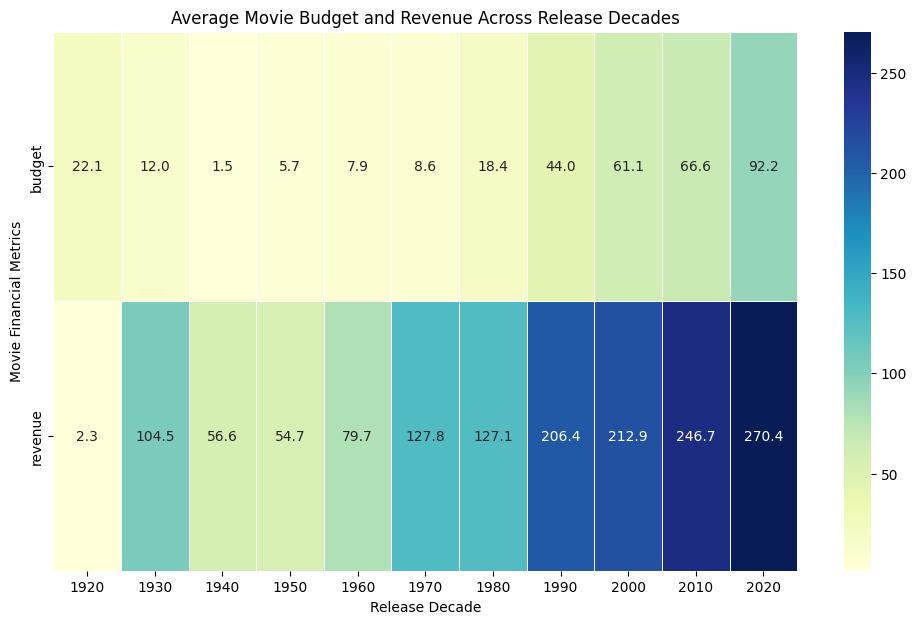

In [47]:
# 9.How do movie budgets and revenues vary across different release decades?
movies['release_year'] = pd.to_datetime(
    movies['release_date'], errors='coerce').dt.year

movies['release_decade'] = (movies['release_year'] // 10) * 10
decade_analysis = movies.groupby('release_decade')[['budget', 'revenue']].mean()

#Create heatmap

plt.figure(figsize=(12, 7))
sns.heatmap(
    decade_analysis.T / 1000000,
    annot=True,
    fmt='.1f',
    cmap='YlGnBu',
    linewidths=0.5
)

plt.title('Average Movie Budget and Revenue Across Release Decades')
plt.xlabel('Release Decade')
plt.ylabel('Movie Financial Metrics')

plt.show()

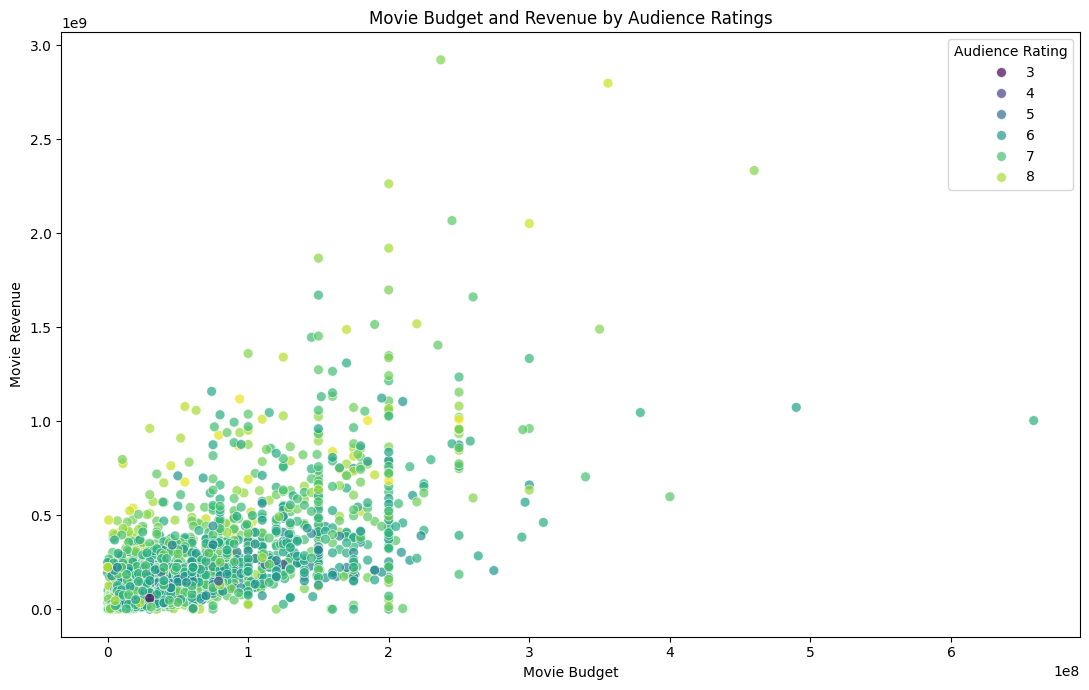

In [41]:
# 10.How do movie budgets and revenues vary according to audience ratings

# Create scatter plot

plt.figure(figsize=(11, 7))
sns.scatterplot(
    data=movies,
    x='budget',
    y='revenue',
    hue='vote_average',
    palette='viridis',
    alpha=0.7,
    s=50
)

plt.title('Movie Budget and Revenue by Audience Ratings')
plt.xlabel('Movie Budget')
plt.ylabel('Movie Revenue')
plt.legend(title='Audience Rating')

plt.tight_layout()
plt.show()

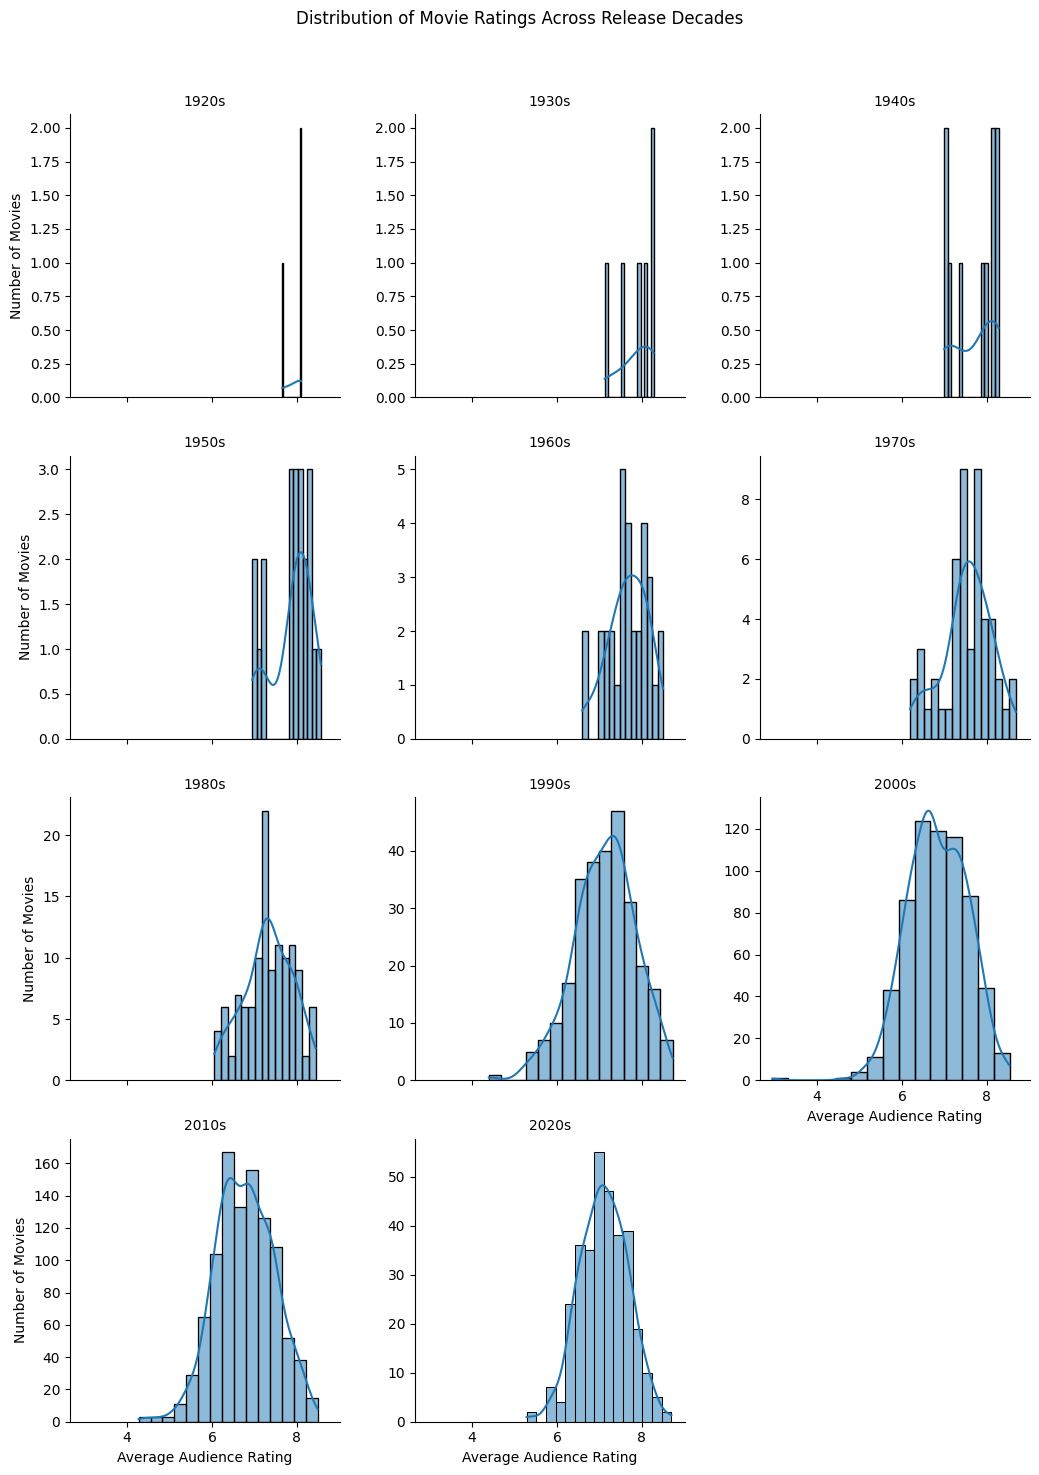

In [43]:
# 11.How does the distribution of audience ratings vary across different release decades
movies['release_year'] = pd.to_datetime(
    movies['release_date'], errors='coerce'
).dt.year

movies['release_decade'] = (
    (movies['release_year'] // 10) * 10
)

# Create FacetGrid with histograms

g = sns.FacetGrid(
    movies,
    col='release_decade',
    col_wrap=3,
    height=3.5,
    sharex=True,
    sharey=False
)
g.map_dataframe(
    sns.histplot,
    x='vote_average',
    bins=15,
    kde=True
)

g.set_axis_labels('Average Audience Rating', 'Number of Movies')
g.set_titles('{col_name}s')

g.fig.suptitle(
    'Distribution of Movie Ratings Across Release Decades',
    y=1.05
)

plt.show()

NameError: name 'result' is not defined

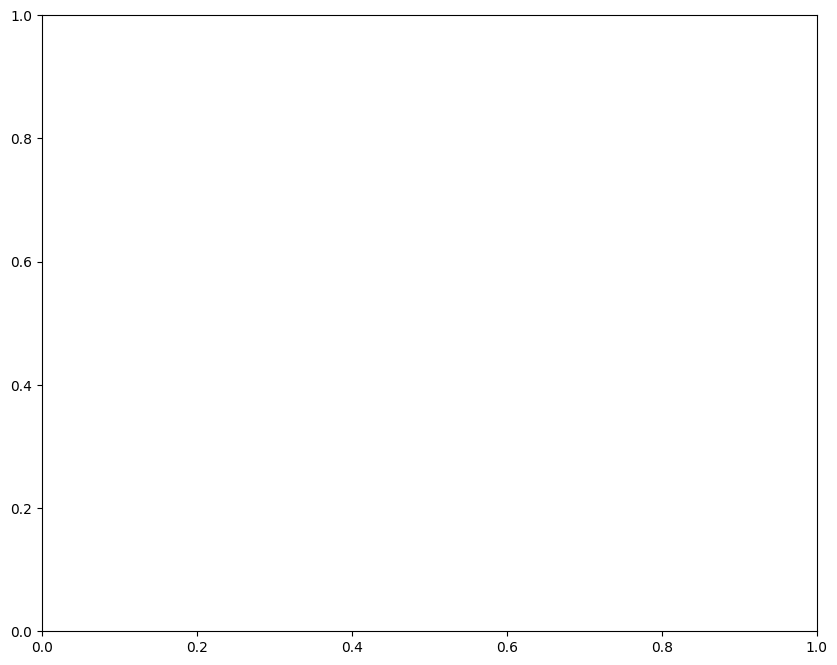

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(10, 8))

ax.pie(
    result["movie_count"],
    labels=result["keyword_name"],
    autopct="%1.1f%%",
    startangle=90
)

ax.set_title("Top 10 Most Frequently Used Keywords")

plt.tight_layout()
st.pyplot(fig)